<a href="https://colab.research.google.com/github/amanpoonia/SBeta_preparation/blob/main/WF_fundamentals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
'''
AIM: Understand walkforward framework for backtesting

Backtest a strategy(MA crossover : Long when when price closes above the moving average and short when it falls below)
Test settings
Performance metrics
'''

/tmp/ipykernel_1115/606989161.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download('^GSPC', start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


Price             Close         High          Low         Open      Volume
Ticker            ^GSPC        ^GSPC        ^GSPC        ^GSPC       ^GSPC
Date                                                                      
2020-01-02  3257.850098  3258.139893  3235.530029  3244.669922  3459930000
2020-01-03  3234.850098  3246.149902  3222.340088  3226.360107  3484700000
2020-01-06  3246.280029  3246.840088  3214.639893  3217.550049  3702460000
2020-01-07  3237.179932  3244.909912  3232.429932  3241.860107  3435910000
2020-01-08  3253.050049  3267.070068  3236.669922  3238.590088  3726840000


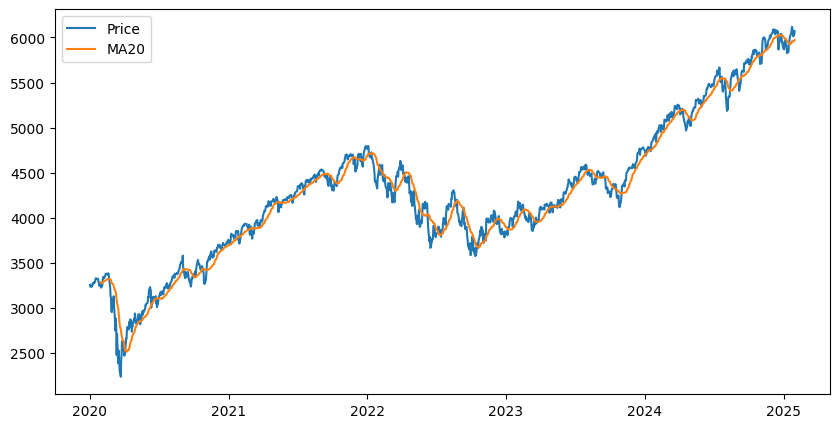

Ticker            ^GSPC         MA20  buy  sell
Date                                           
2020-01-02  3257.850098          NaN    0     0
2020-01-03  3234.850098          NaN    0     0
2020-01-06  3246.280029          NaN    0     0
2020-01-07  3237.179932          NaN    0     0
2020-01-08  3253.050049          NaN    0     0
2020-01-09  3274.699951          NaN    0     0
2020-01-10  3265.350098          NaN    0     0
2020-01-13  3288.129883          NaN    0     0
2020-01-14  3283.149902          NaN    0     0
2020-01-15  3289.290039          NaN    0     0
2020-01-16  3316.810059          NaN    0     0
2020-01-17  3329.620117          NaN    0     0
2020-01-21  3320.790039          NaN    0     0
2020-01-22  3321.750000          NaN    0     0
2020-01-23  3325.540039          NaN    0     0
2020-01-24  3295.469971          NaN    0     0
2020-01-27  3243.629883          NaN    0     0
2020-01-28  3276.239990          NaN    0     0
2020-01-29  3273.399902          NaN    

In [45]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

start_date = '2020-01-01'
end_date = '2025-01-31'

data = yf.download('^GSPC', start=start_date, end=end_date)
print(data.head())

#rolling average of the last 20 days
price = data['Close'].copy()

price['MA20'] = price['^GSPC'].rolling(20).mean()

#plotting MA with prices
plt.figure(figsize=(10, 5))
plt.plot(price['^GSPC'], label='Price')
plt.plot(price['MA20'], label='MA20')
plt.legend()
plt.show()

#initial portfolio
port_i = 100

#trading, trades at crossover
price['buy'] = np.where(price['^GSPC'] > price['MA20'], 1, 0)
price['sell'] = np.where(price['^GSPC'] < price['MA20'], 1, 0)

print(price.head(21))

In [55]:
price['return'] = np.log(price['^GSPC']/price['^GSPC'].shift(1))
price.dropna(inplace=True)
price['pf_value'] = price['^GSPC']*(1+price['return'].cumsum())
price

Ticker,^GSPC,MA20,buy,sell,return,pf_value
Date,,,,,,
2020-01-31,3225.520020,3279.220496,0,1,-0.017864,3167.897899
2020-02-03,3248.919922,3279.923987,0,1,0.007228,3214.364352
2020-02-04,3297.590088,3282.489490,1,0,0.014869,3311.549770
2020-02-05,3334.689941,3287.364990,1,0,0.011188,3386.114451
2020-02-06,3345.780029,3292.001489,1,0,0.003320,3408.484068
...,...,...,...,...,...,...
2025-01-24,6101.240234,5959.818018,1,0,-0.002859,9881.162588
2025-01-27,6012.279785,5958.430005,1,0,-0.014688,9648.779445
2025-01-28,6067.700195,5959.935522,1,0,0.009176,9793.395692


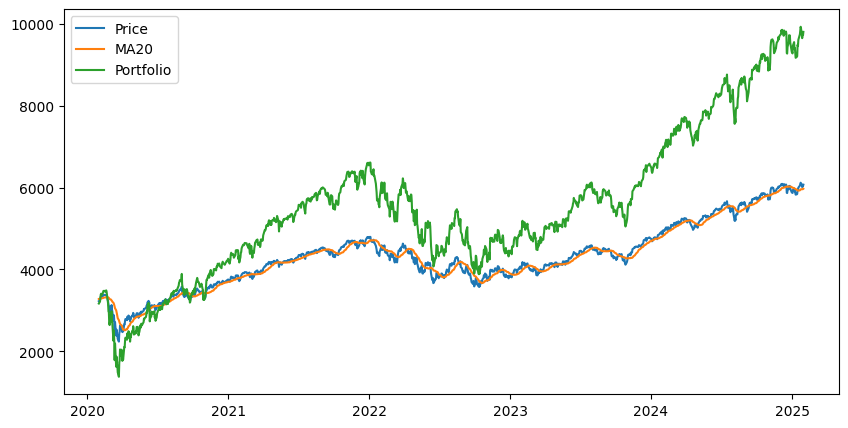

In [56]:
'''
portfolio_i = 3283

buy_ret = np.cumsum(np.where(price['buy'] == 1, price['return'], 0))
buy_ret
sell_ret = -np.cumsum(np.where(price['sell'] == 1, price['return'], 0))
sell_ret

portfolio_ret = (1 + buy_ret + sell_ret) * portfolio_i
portfolio_ret
'''
plt.figure(figsize=(10, 5))
plt.plot(price['^GSPC'], label='Price')
plt.plot(price['MA20'], label='MA20')
plt.plot(price['pf_value'], label='Portfolio')
plt.legend()
plt.show()